<div dir="rtl" style="text-align:right">

# 🧪 مشروع مصغّر: هل التغريدة العربية إيجابية أم سلبية؟ (نموذج بسيط ضد شبكة عصبية)
### (تمرين بالنسخ واللصق من دفتر الدراسة الذاتية Part A)

**السيناريو:** شركة تريد قياس رأي الجمهور من تغريدات مكتوبة بلهجات عربية متعددة. المطلوب منك بناء نموذجين على مجموعة **التغريدات العربية** والمقارنة بينهما. الملف `ar_tweets.csv` يزوّدك به المدرّس: عمود `text` (التغريدة) وعمود `label` (‏1 = إيجابية، 0 = سلبية).

### 📌 كيف تعمل؟
- **لا تحتاج إلى كتابة أي كود جديد.** كل الأكواد المطلوبة موجودة في دفتر الدراسة الذاتية: `Text_Classification_Part_A_From_Words_to_Numbers`. دورك: **ابحث عن الخلية، انسخها، الصقها هنا، غيّر فقط ما يُطلب منك، ثم شغّلها.**
- لكل خطوة نذكر لك: **القسم (Section)** الذي تنسخ منه، وكيف تتعرف على الخلية (**أول سطر فيها**).
- شغّل الخلايا **بالترتيب من الأعلى إلى الأسفل**. المهام تعتمد على بعضها.
- كل ما هو مطلوب كتابته بنفسك هو **ملاحظاتك وإجاباتك** في الخلايا النصية (✏️).

### 🗺️ دليل المصادر: أين تجد كل خلية؟
| خطوة التمرين | القسم في دفتر الدراسة الذاتية |
|---|---|
| 0. تحميل البيانات | سطر جاهز يعطيك إياه التمرين |
| 1. تقسيم البيانات | القسم 2: *A baseline model* |
| 2. النموذج الأساسي (Baseline) | القسم 2 |
| 3. الكلمات الأكثر تأثيراً | القسم 2 (تحت 👀 Observe) |
| 4. الشبكة العصبية | القسم 3: *A neural network on word counts* |
| 5. المقارنة والاستنتاج | تكتبه بنفسك |
| 6. التشابه بين الجمل | القسم 4: *From word counts to word embeddings* |

### 🎯 النتائج المطلوبة عند الانتهاء
1. دقة (accuracy) النموذج الأساسي على بيانات الاختبار.
2. أكثر الكلمات سلبية وأكثرها إيجابية.
3. دقة الشبكة العصبية بعد اختيار عدد مناسب من الـ epochs.
4. استنتاج قصير يستخدم **عدد الجمل** وليس النسبة فقط.
5. قيم التشابه بين جمل من بيانات التدريب.

</div>

<div dir="rtl" style="text-align:right">

## المهمة 0: تحميل البيانات (كود جاهز)
ارفع الملف `ar_tweets.csv` إلى بيئة العمل (في Colab: أيقونة المجلد على اليسار ثم Upload). ثم شغّل الخلية التالية كما هي:

</div>

In [1]:
import pandas as pd

df = pd.read_csv("ar_tweets.csv")
df.head()

,text,label
0,اربد فيها جامعات اكثر من عمان ... وفيها قد عم...,1
1,الحلو انكم بتحكوا على اساس انو الاردن ما فيه ...,0
2,كله رائع بجد ربنا يكرمك,1
3,لسانك قذر يا قمامه,0
4,​انا داشره وغير متزوجه ولدي علاقات مشبوه واحشش...,0


<div dir="rtl" style="text-align:right">

## المهمة 1: تقسيم البيانات (تدريب 75% / اختبار 25%)
انسخ من **القسم 2** (*A baseline model: bag of words + logistic regression*) **أول خلية كود**، وهي التي تبدأ بـ:

```
from sklearn.model_selection import train_test_split
```

**التعديل المطلوب:** هذه الخلية تعمل على بيانات yelp، وبياناتنا في الجدول `df` الذي له عمودان `text` و `label`. لذلك:
- **احذف** السطر `df_yelp = df[df['source'] == 'yelp']`.
- اجعل `sentences = df['text'].values`
- واجعل `y = df['label'].values`

والباقي (استدعاء `train_test_split`) يبقى كما هو.

ثم أضف في آخر الخلية سطراً تطبع فيه عدد جمل التدريب وعدد جمل الاختبار:
`print(len(sentences_train), len(sentences_test))`

</div>

In [6]:
# الصق هنا خلية train_test_split من القسم 2 وعدّلها كما في التعليمات
from sklearn.model_selection import train_test_split

X = df['text'].values
y = df['label'].values
sentences_train, sentences_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1000)
print(len(sentences_train), len(sentences_test))

1350 450


<div dir="rtl" style="text-align:right">

## المهمة 2: النموذج الأساسي (Baseline)
انسخ من **القسم 2** خليتين وشغّلهما بالترتيب **دون أي تعديل**:

1. الخلية التي تبدأ بـ `from sklearn.feature_extraction.text import CountVectorizer` وفيها `vectorizer = CountVectorizer()` و`vectorizer.fit(sentences_train)` وتنتهي بالسطر `X_train`.
   (انتبه: في القسم 2 خليتان تبدآن بنفس السطر. المطلوب هي التي فيها `vectorizer = CountVectorizer()`، وليست التي فيها `toy = [...]`.)
2. الخلية التي تبدأ بـ `from sklearn.linear_model import LogisticRegression` وتطبع `Accuracy:`.

✏️ **اكتب هنا دقة النموذج الأساسي:** 82.8%

</div>

In [7]:
# الخلية 1: الصق هنا خلية CountVectorizer من القسم 2
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
vectorizer.fit(sentences_train)

X_train = vectorizer.transform(sentences_train)
X_test  = vectorizer.transform(sentences_test)
X_train

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 11389 stored elements and shape (1350, 5535)>

In [8]:
# الخلية 2: الصق هنا خلية LogisticRegression من القسم 2
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression()
classifier.fit(X_train, y_train)
score = classifier.score(X_test, y_test)

print("Accuracy:", score)

Accuracy: 0.8288888888888889


<div dir="rtl" style="text-align:right">

## المهمة 3: انظر داخل النموذج الأساسي
انسخ من **القسم 2** الخلية الموجودة تحت العنوان **👀 Observe** (بعد خلية الدقة)، وهي التي تبدأ بـ:

```
import numpy as np
```
وفيها `words = np.array(vectorizer.get_feature_names_out())`.

شغّلها **دون تعديل**، فهي تطبع أكثر 10 كلمات سلبية وأكثر 10 كلمات إيجابية.

✏️ **ملاحظاتك:** هل الكلمات منطقية؟ هل ظهرت كلمات مفاجئة؟ لماذا برأيك؟ (تلميح: حجم بيانات التدريب صغير.)

نعم بعضها منطقي ، في الايجابية يوجد " احلى ، الحمد، الله، جميل ..."

في السلبية "حرام - جهنم- عاهات - "

باقي الكلمات تأتي في السياقين، مثلا ولا - اللي - حد - واحد - ربنا - شو - مش ..."
المودل لسا ما قدر يعمم لقلة البيانات
</div>

In [9]:
# الصق هنا خلية الكلمات من القسم 2
import numpy as np

words = np.array(vectorizer.get_feature_names_out())
order = np.argsort(classifier.coef_[0])      # smallest (most negative) weight first
print("Most negative words:", list(words[order[:10]]))
print("Most positive words:", list(words[order[-10:]]))

Most negative words: ['شو', 'مش', 'عاهات', 'حرام', 'جهنم', 'واحد', 'ولا', 'اللي', 'والله', 'حد']
Most positive words: ['احلى', 'الحمد', 'الله', 'جميل', 'رب', 'كلام', 'صباح', 'يارب', 'ربنا', 'اللهم']


<div dir="rtl" style="text-align:right">

## المهمة 4: شبكة عصبية على عدد الكلمات
انسخ من **القسم 3** (*A neural network on word counts*) الخلايا التالية **بالترتيب**، وشغّل كل واحدة بعد لصقها:

| # | كيف تتعرف عليها | ماذا تفعل |
|---|---|---|
| 4أ | تبدأ بـ `import keras` وفيها `Sequential` و `Dense(10` | بناء النموذج |
| 4ب | تبدأ بـ `model.compile(` | تجهيز النموذج |
| 4ج | تبدأ بـ `from scipy.sparse import issparse` | تحويل البيانات إلى مصفوفات عادية |
| 4د | تبدأ بـ `history = model.fit(` | التدريب (100 epoch) |
| 4هـ | تبدأ بـ `import matplotlib.pyplot as plt` وفيها `def plot_history(history):` | تعريف دالة الرسم |
| 4و | تحتوي سطراً واحداً: `plot_history(history)` | رسم المنحنيات |

> ⚠️ هذه الخلايا تستخدم المتغيرات `X_train` و `X_test` و `y_train` و `y_test` التي أنشأتها في المهمتين 1 و 2، لذلك **لا تغيّر أسماءها**.

</div>

In [10]:
# 4أ: الصق خلية بناء النموذج (import keras ...)
import keras
from keras.models import Sequential
from keras import layers

input_dim = X_train.shape[1]  # Number of features
print('features#', input_dim)

model = Sequential()
model.add(layers.Input(shape=(input_dim,)))
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

features# 5535


In [11]:
# 4ب: الصق خلية model.compile
model.compile(loss='binary_crossentropy',
               optimizer='adam',
               metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,371 (216.29 KB)

 Trainable params: 55,371 (216.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# 4ج: الصق خلية issparse
from scipy.sparse import issparse

# change the sparse matrices to normal float arrays (only if they are still sparse)
if issparse(X_train):
    X_train = X_train.toarray().astype('float32')
    X_test = X_test.toarray().astype('float32')

In [13]:
# 4د: الصق خلية model.fit (100 epoch)
history = model.fit(X_train, y_train,
                     epochs=100,
                     verbose=False,
                     validation_split = 0.2,
                     batch_size=10)

In [14]:
# 4هـ: الصق خلية تعريف plot_history
import matplotlib.pyplot as plt
plt.style.use('ggplot')

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()

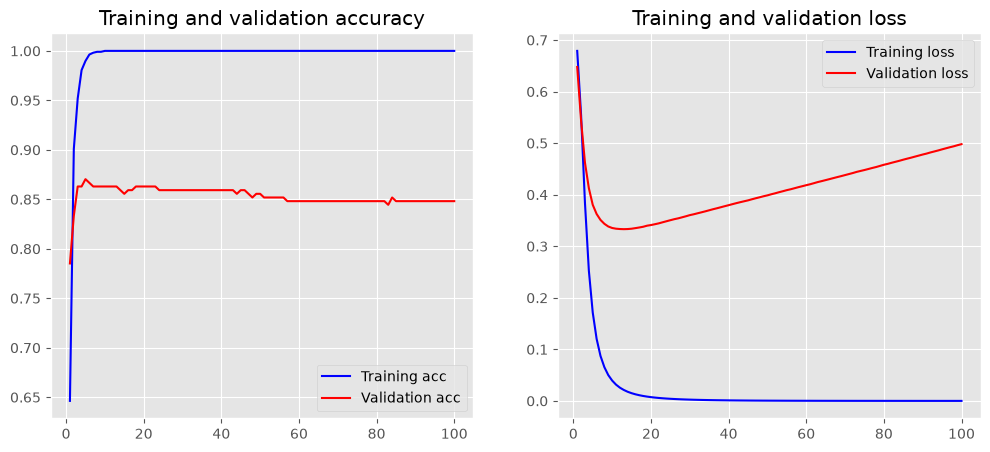

In [15]:
# 4و: الصق خلية plot_history(history)
plot_history(history)

<div dir="rtl" style="text-align:right">

### اختيار عدد الـ epochs المناسب
انظر إلى الرسم الأيمن (Loss). **عند أي epoch يكون خط الـ Validation loss (الأحمر) أقل ما يمكن؟** بعد هذه النقطة يرتفع الخط الأحمر بينما ينزل الأزرق، وهذا هو **Overfitting**.

✏️ **أفضل epoch برأيي:** 13 &nbsp;&nbsp; (إذا كان المنحنى متذبذباً، فاختر رقماً قريباً بين 5 و 15.)

### تدريب نموذج جديد بالعدد المناسب
انسخ من **القسم 3** الخلية الموجودة تحت العنوان **🛠️ Modify**، وهي التي تبدأ بـ:

```
EPOCHS = 10     # TODO: try 3, 10, 100
```
غيّر **قيمة `EPOCHS` فقط** إلى الرقم الذي اخترته، ثم شغّلها. هذه الخلية تبني نموذجاً **جديداً** وتطبع دقته على بيانات الاختبار: `test accuracy = ...`

✏️ **دقة الشبكة العصبية على الاختبار:** 86.6%

</div>

epochs = 13   test accuracy = 0.8644


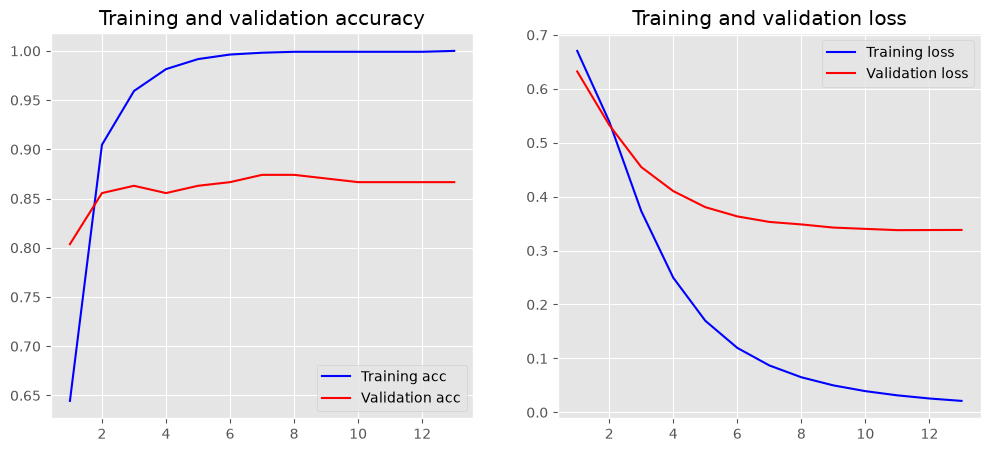

In [48]:
# الصق هنا خلية EPOCHS من القسم 3 (Modify) وعدّل قيمة EPOCHS فقط
EPOCHS = 13     

tmp_model = Sequential()
tmp_model.add(layers.Input(shape=(input_dim,)))
tmp_model.add(layers.Dense(10, activation='relu'))
tmp_model.add(layers.Dense(1, activation='sigmoid'))
tmp_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

tmp_history = tmp_model.fit(X_train, y_train, epochs=EPOCHS, verbose=False,
                            validation_split=0.2, batch_size=10)
loss, acc = tmp_model.evaluate(X_test, y_test, verbose=False)
print("epochs = {}   test accuracy = {:.4f}".format(EPOCHS, acc))
plot_history(tmp_history)

<div dir="rtl" style="text-align:right">

## المهمة 5: المقارنة والاستنتاج
(هذه المهمة بدون كود جديد، تحسبها بنفسك.)

املأ الجدول بالأرقام التي حصلت عليها:


| النموذج | دقة الاختبار |
|---|---|
| Logistic Regression + CountVectorizer (المهمة 2) | 82.8% |
| Dense network (المهمة 4) | 86.6% |

**عدد جمل الاختبار:** شغّل في خلية الكود أدناه `len(y_test)` لتعرفه.

**الفرق بعدد الجمل = (الفرق بين الدقتين) × (عدد جمل الاختبار)** 17

✏️ **استنتاجك (2–3 جمل):** أي النموذجين أفضل؟ بكم؟ هل تثق بهذا الفرق؟ تذكّر أن بيانات الاختبار **صغيرة** وأن أوزان الشبكة تبدأ **عشوائياً**، فتتغير النتيجة قليلاً في كل تشغيل.

الشبكة العصبية افضل ب 17 تغريدة (4% تقريبا) - لا يوثق به لقلة البيانات

</div>

In [18]:
print(len(y_test))
print(3.8 * len(y_test) / 100)

450
17.1


<div dir="rtl" style="text-align:right">

## المهمة 6: التشابه بين الجمل (Cosine Similarity)
الآن كل جملة تدريب هي صف في المصفوفة `X_train` (بعد المهمة 4ج صارت مصفوفة عادية). سنقيس التشابه بين جمل التدريب.

1. انسخ من **القسم 4** (*From word counts to word embeddings*) أول خلية تعرّف `cosine_similarity`، وهي التي تبدأ بـ:
   ```
   import numpy as np
   euclidean_distance = lambda x, y: ...
   cosine_similarity = lambda x, y: ...
   ```
   (تجدها بعد الفقرة التي تبدأ بـ *Cosine similarity is good when the length of the vectors does not matter*.)
2. في خلية جديدة، استخدم الدالة بنفس طريقة الخلية `print("cosine(a, b) =", ...)` الموجودة بعدها في القسم 4. لكن **استبدل** `doc_a` و `doc_b` بصفوف من `X_train`، أي `X_train[0]` و `X_train[1]`. اطبع أيضاً الجملتين نفسيهما: `sentences_train[0]` و `sentences_train[1]`.
3. كرّر ذلك لثلاثة أزواج مختلفة من الجمل، مثل: (0, 1) و (0, 2) و (1, 2).

✏️ **ملاحظاتك:** أي زوج جمل كان الأكثر تشابهاً؟ هل التشابه يعني بالضرورة أن للجملتين **نفس المشاعر**؟ (إذا ظهرت `nan` فمعناه أن إحدى الجملتين لا تحتوي أي كلمة معروفة، فمتجهها كله أصفار.)

........

</div>

<div dir="rtl" style="text-align:right">

y_train[0] = 0
y_train[1] = 0
y_train[2] = 1

اول محاولة:

قصدك اخر ما توصل اليه العقل البشري من تفاهات

يلعن ام الازعاج

euclidean(a, b) = 3.46

cosine(a, b)    = 0.0


ثاني محاولة : 

قصدك اخر ما توصل اليه العقل البشري من تفاهات

يا سلام على الوفاء اللي اتفقد في عصرنا ويا حسرتاه على الحب الذي بات مجرد كلمات

euclidean(a, b) = 5.2

cosine(a, b)    = 0.0


ثالث محاولة : 

يلعن ام الازعاج

يا سلام على الوفاء اللي اتفقد في عصرنا ويا حسرتاه على الحب الذي بات مجرد كلمات

euclidean(a, b) = 4.58

cosine(a, b)    = 0.0

جميع الجمل غير متشابهة من ناحية ال cosine similarity 

ولكن لا يعني التشابه بالضرورة نفس ان للجملتين نفس المشاعر

الجملة الاولى والثانية لا يوجد تشابه بينهما من ناحية ال cosine similarity

لكن من ناحية ال eculidan distance فالفرق بين السلبية اقل من السلبية 
والايجابية

</div>


In [19]:
# الصق هنا خلية cosine_similarity من القسم 4
import numpy as np
euclidean_distance = lambda x, y: np.sqrt(np.sum((x - y) ** 2))
cosine_similarity = lambda x, y: np.dot(x, y) / (np.sqrt(np.dot(x, x)) * np.sqrt(np.dot(y, y)))

In [38]:

best = []
for i in range(100):
  for j in range(i+1, 100):
    if i==j: continue
    
    doc_a = X_train[i]
    doc_b = X_train[j]                  # same topic, ten times longer
    best.append({
      "cosine" :  round(float(cosine_similarity(doc_a, doc_b)), 2),
      "ecu" :  round(float(euclidean_distance(doc_a, doc_b)), 2),
      "i" : i, 
      "j" : j
    })

best.sort(key = lambda x : x['cosine'], reverse=True)    
for x in best[:3]:
  print(x)
  print(sentences_train[x['i']])
  print(sentences_train[x['j']])

{'cosine': 0.58, 'ecu': 1.73, 'i': 70, 'j': 86}
ما اجمل الاخاء
ما اجمل ديننا الاسلامي
{'cosine': 0.53, 'ecu': 3.46, 'i': 20, 'j': 90}
يا رب خد بيدنا يا جبرنا يا جبار السموات والارض
يا خساره عليكو يا شباب المستقبل
{'cosine': 0.53, 'ecu': 3.74, 'i': 20, 'j': 99}
يا رب خد بيدنا يا جبرنا يا جبار السموات والارض
يا رب قويني علي نفسي يا رب تقبل منا الله


<div dir="rtl" style="text-align:right">

## ⭐ مهام إضافية (بالنسخ فقط أيضاً)
1. **تأثير طريقة تحويل النص:** انسخ من **القسم 2** الخلية الموجودة تحت **🛠️ Modify**، وهي التي تبدأ بـ `# TODO: try these, one at a time:`. جرّب ثلاثة خيارات للـ `CountVectorizer`: الافتراضي، `min_df=2`، `ngram_range=(1, 2)`، وسجّل الدقة لكل خيار. أيها حسّن النتيجة؟ ثم جرّب `stop_words='english'` وقارن: ما الذي تغيّر ولماذا؟ (فكّر: هل في تغريداتنا كلمات إنجليزية؟)
2. **تأثير عدد الـ epochs:** أعد خلية `EPOCHS` من المهمة 4 بالقيم 3 و 10 و 100، وسجّل الدقة في كل مرة. ماذا يحدث عند 100؟
3. **التذبذب بين التشغيلات:** شغّل خلية `EPOCHS` خمس مرات بنفس القيمة. كم تتغير الدقة؟ وماذا يعني ذلك لثقتك في الفرق بين النموذجين؟

## 📦 التسليم
ملف الدفتر بعد تشغيل كل الخلايا، وفيه ملاحظاتك المكتوبة في المهام 2 و 3 و 4 و 5 و 6.

</div>

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# TODO: try these, one at a time:
#   CountVectorizer()                        (the default)
#   CountVectorizer(stop_words='english')
#   CountVectorizer(min_df=2)                (ignore words that appear in fewer than 2 sentences)
#   CountVectorizer(ngram_range=(1, 2))      (use single words AND pairs of words)
try_vec = CountVectorizer(stop_words='arabic')

try_vec.fit(sentences_train)
X_tr_try = try_vec.transform(sentences_train)
X_te_try = try_vec.transform(sentences_test)

try_clf = LogisticRegression()
try_clf.fit(X_tr_try, y_train)
print("features:", X_tr_try.shape[1], "  test accuracy:", round(try_clf.score(X_te_try, y_test), 4))

features: 5535   test accuracy: 0.8289


In [39]:
try_vec = CountVectorizer(min_df=2)

try_vec.fit(sentences_train)
X_tr_try = try_vec.transform(sentences_train)
X_te_try = try_vec.transform(sentences_test)

try_clf = LogisticRegression()
try_clf.fit(X_tr_try, y_train)
print("features:", X_tr_try.shape[1], "  test accuracy:", round(try_clf.score(X_te_try, y_test), 4))

features: 1297   test accuracy: 0.8333


In [40]:
try_vec =CountVectorizer(ngram_range=(1, 2))

try_vec.fit(sentences_train)
X_tr_try = try_vec.transform(sentences_train)
X_te_try = try_vec.transform(sentences_test)

try_clf = LogisticRegression()
try_clf.fit(X_tr_try, y_train)
print("features:", X_tr_try.shape[1], "  test accuracy:", round(try_clf.score(X_te_try, y_test), 4))

features: 15228   test accuracy: 0.8244


In [42]:
try_vec =CountVectorizer(stop_words=['مش','لا'])

try_vec.fit(sentences_train)
X_tr_try = try_vec.transform(sentences_train)
X_te_try = try_vec.transform(sentences_test)

try_clf = LogisticRegression()
try_clf.fit(X_tr_try, y_train)
print("features:", X_tr_try.shape[1], "  test accuracy:", round(try_clf.score(X_te_try, y_test), 4))

features: 5533   test accuracy: 0.8311


epochs = 3   test accuracy = 0.8378


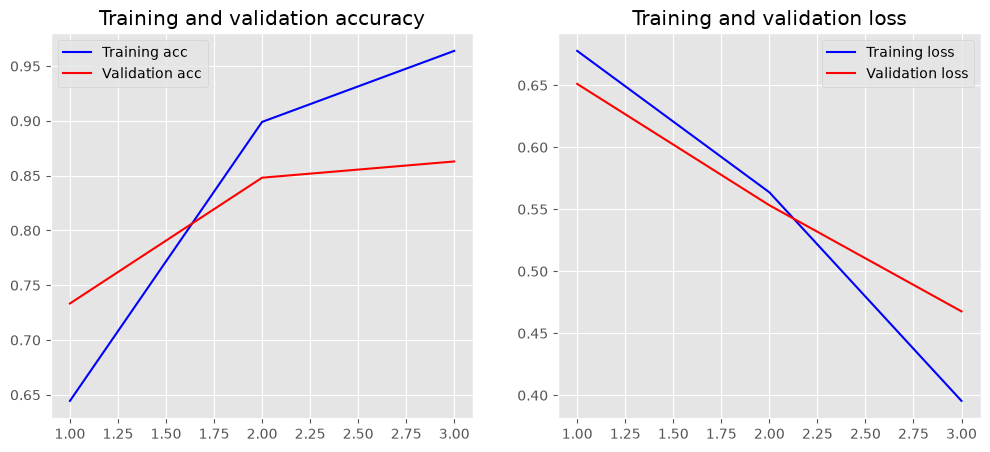

In [43]:
# الصق هنا خلية EPOCHS من القسم 3 (Modify) وعدّل قيمة EPOCHS فقط
EPOCHS = 3     

tmp_model = Sequential()
tmp_model.add(layers.Input(shape=(input_dim,)))
tmp_model.add(layers.Dense(10, activation='relu'))
tmp_model.add(layers.Dense(1, activation='sigmoid'))
tmp_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

tmp_history = tmp_model.fit(X_train, y_train, epochs=EPOCHS, verbose=False,
                            validation_split=0.2, batch_size=10)
loss, acc = tmp_model.evaluate(X_test, y_test, verbose=False)
print("epochs = {}   test accuracy = {:.4f}".format(EPOCHS, acc))
plot_history(tmp_history)

epochs = 10   test accuracy = 0.8578


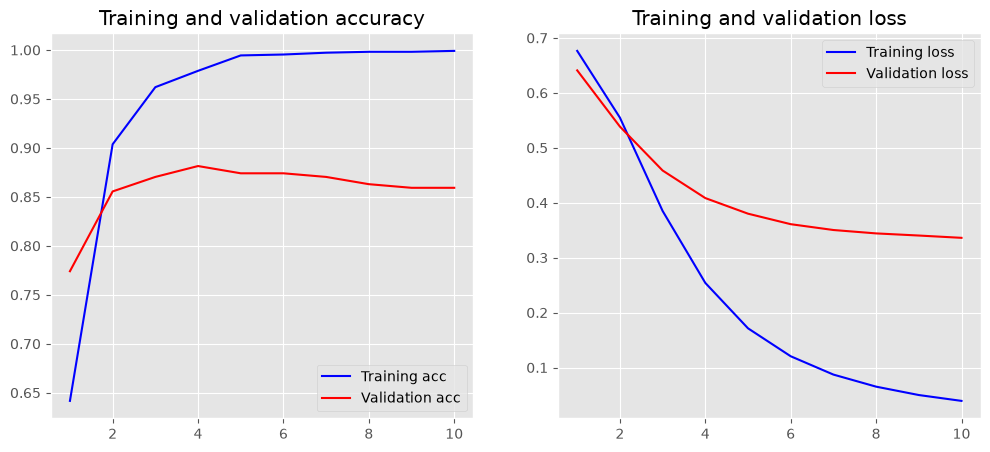

In [44]:
# الصق هنا خلية EPOCHS من القسم 3 (Modify) وعدّل قيمة EPOCHS فقط
EPOCHS = 10     

tmp_model = Sequential()
tmp_model.add(layers.Input(shape=(input_dim,)))
tmp_model.add(layers.Dense(10, activation='relu'))
tmp_model.add(layers.Dense(1, activation='sigmoid'))
tmp_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

tmp_history = tmp_model.fit(X_train, y_train, epochs=EPOCHS, verbose=False,
                            validation_split=0.2, batch_size=10)
loss, acc = tmp_model.evaluate(X_test, y_test, verbose=False)
print("epochs = {}   test accuracy = {:.4f}".format(EPOCHS, acc))
plot_history(tmp_history)

epochs = 100   test accuracy = 0.8622


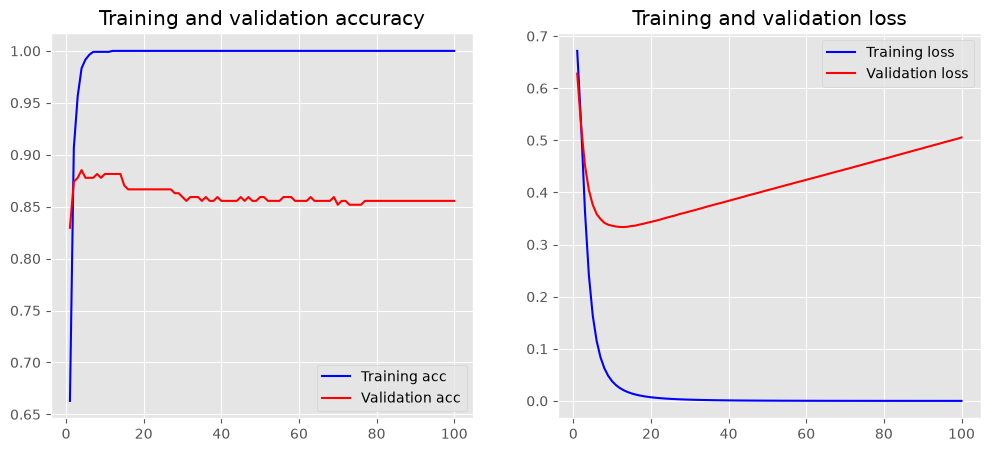

In [45]:
# الصق هنا خلية EPOCHS من القسم 3 (Modify) وعدّل قيمة EPOCHS فقط
EPOCHS = 100     

tmp_model = Sequential()
tmp_model.add(layers.Input(shape=(input_dim,)))
tmp_model.add(layers.Dense(10, activation='relu'))
tmp_model.add(layers.Dense(1, activation='sigmoid'))
tmp_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

tmp_history = tmp_model.fit(X_train, y_train, epochs=EPOCHS, verbose=False,
                            validation_split=0.2, batch_size=10)
loss, acc = tmp_model.evaluate(X_test, y_test, verbose=False)
print("epochs = {}   test accuracy = {:.4f}".format(EPOCHS, acc))
plot_history(tmp_history)